# Inferring Local Genealogies and Ancestor Ages

Can the observed DNA recover ancestry along a recombining chromosome?
Generate linked ancestry and mutations, then give only phased sequences,
variant positions and analyzed length to the inference functions.
Compare the inferred local trees and estimated ages with separate simulation records.


In [1]:
library(hpgR)
options(repr.plot.width = 10, repr.plot.height = 4.5,
        repr.plot.pointsize = 14, warn = 1)
truth_color <- "#B33B32"
estimate_color <- "#265991"
drawFigure <- function(name, draw, width = 10, height = 4.5) {
    options(repr.plot.width = width, repr.plot.height = height)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width,
            height = height, pointsize = 14, family = "Helvetica",
            useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


## Generate ancestry, then mutations

Four diploid people give eight sampled haploid copies. Set diploid
$N_e=1,000$, $L=100,000$ bases, crossover rate $r=10^{-8}$ per base per
generation and mutation rate $\mu=2\times10^{-7}$ per base per generation.
The elevated mutation rate makes a short region informative.

With $k$ lineages and no recombination, the merger waiting time has rate
$\binom{k}{2}/(2N_e)$. Backward recombination splits a lineage's genomic
material; coalescence joins ancestral lineages. The Hudson algorithm in hpgR
generates the linked ancestry. Conditional on it, mutations arrive on
branches as a Poisson process. Continuous positions give infinite sites.

Seeds are fixed before inspecting the realization. Record the full ARG;
keep node and edge truth separate from the final sequence observations.


In [2]:
design <- list(samples = 4L, Ne = 1000, length = 100000,
               recombination_rate = 1e-8, mutation_rate = 2e-7)
ancestry <- simulateAncestry(design$samples, design$Ne, design$length,
    design$recombination_rate, seed = 20261104L, recordFullArg = TRUE)
sequences <- mutateAncestry(ancestry, design$mutation_rate, seed = 20261105L)
truth <- ancestryData(sequences)
observed <- truth$observed
print(c(haploid_copies = truth$nHaplotypes, variant_sites = truth$nSites,
    recorded_intervals = truth$nRecordedTrees, local_trees = truth$nTrees,
    recorded_recombination_nodes = truth$recombinationNodes))
stopifnot(nrow(observed$haplotypes) == 8L, truth$nSites > 0L,
          !anyDuplicated(observed$positions), truth$nTrees > 1,
          !any(c("nodes", "edges", "intervals", "Ne") %in% names(observed)))


              haploid_copies                variant_sites           recorded_intervals                  local_trees 
                           8                          262                           20                           14 
recorded_recombination_nodes 
                          38 


## Read the recorded local trees

The full ARG contains coalescent and recombination nodes. Local-tree displays
suppress unary nodes while retaining sampled relationships and ages.
Some recorded events leave these relationships unchanged, so the full record
can have more intervals than the display.
Node IDs identify ancestral copies. The sampled copies retain labels S1–S8.


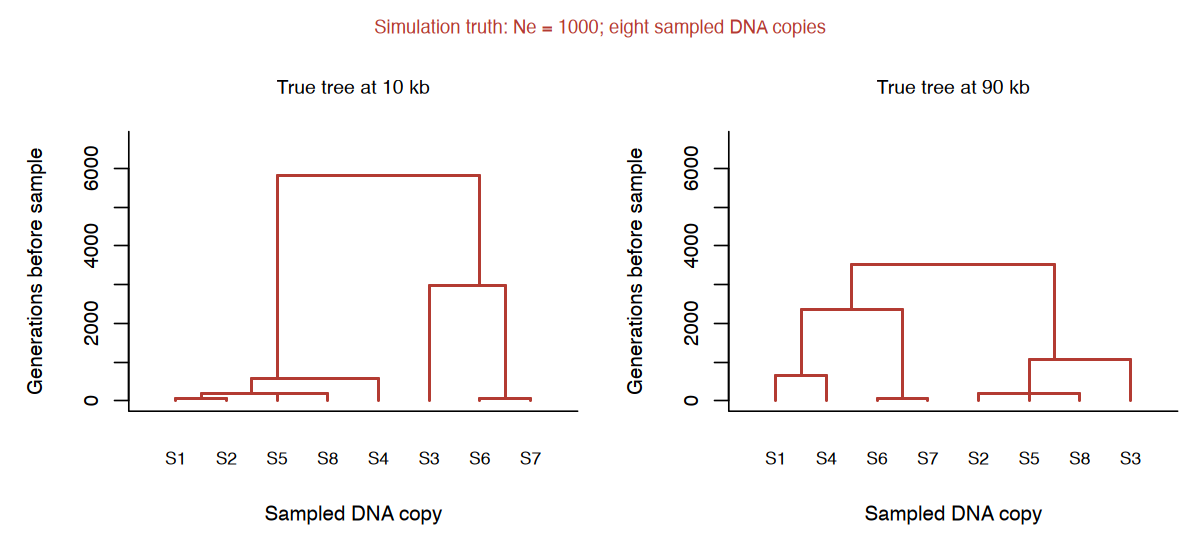

In [3]:
treePositions <- function(nodes) {
    samples <- nodes$node[nodes$is_sample]
    paths <- lapply(samples, function(node) {
        path <- node
        while (nodes$parent[match(node, nodes$node)] >= 0L) {
            node <- nodes$parent[match(node, nodes$node)]
            path <- c(path, node)
        }
        path
    })
    tipOrder <- integer()
    visit <- function(node) {
        if (node %in% samples) tipOrder <<- c(tipOrder, node)
        for (child in nodes$node[nodes$parent == node]) visit(child)
    }
    for (root in nodes$node[nodes$parent == -1L]) visit(root)
    vapply(nodes$node, function(node) {
        children <- tipOrder[vapply(tipOrder, function(sample)
            node %in% paths[[match(sample, samples)]], logical(1))]
        mean(range(match(children, tipOrder)))
    }, numeric(1))
}

drawTree <- function(nodes, title, color, ymax) {
    nodes$x <- treePositions(nodes)
    plot(NA, xlim = c(.4, 8.6), ylim = c(0, ymax), xaxt = "n",
         xlab = "Sampled DNA copy", ylab = "Generations before sample",
         main = title, cex.main = .95, bty = "l")
    for (i in which(nodes$parent >= 0)) {
        parent <- match(nodes$parent[i], nodes$node)
        segments(nodes$x[i], nodes$time[i], nodes$x[i], nodes$time[parent],
                 col = color, lwd = 1.8)
        segments(nodes$x[i], nodes$time[parent], nodes$x[parent],
                 nodes$time[parent], col = color, lwd = 1.8)
    }
    tips <- nodes$is_sample
    axis(1, nodes$x[tips], paste0("S", nodes$node[tips] + 1L),
         tick = FALSE, cex.axis = .85)
}
positions <- c(10000, 90000)
tree_indices <- findInterval(positions, truth$intervals$left)
drawFigure("population_arg_trees", function() {
    par(mfrow = c(1, 2), mar = c(4.6, 4.6, 3.2, .8), oma = c(0, 0, 1.5, 0))
    for (j in seq_along(positions)) drawTree(truth$localTrees[[tree_indices[j]]],
        paste("True tree at", positions[j] / 1000, "kb"), truth_color,
        max(truth$intervals$tmrca) * 1.1)
    mtext("Simulation truth: Ne = 1000; eight sampled DNA copies", outer = TRUE,
          side = 3, line = .2, col = truth_color, cex = .9)
})


## Infer the local genealogies

Shared derived variants identify candidate ancestors. The source ancestor
builder groups focal sites by their carrier patterns and derived frequencies,
then extends each ancestor using consensus among those carriers.

Match older ancestors first with the Li–Stephens copying HMM. Then match the
observed copies against the ancestral sequences. The fitted copying paths
give parent–child edges over genomic intervals. Initial node times give an
ordering of ancestors. The matcher probabilities control copying and mismatch.


In [4]:
inferred <- inferAncestry(observed$haplotypes, observed$positions,
    observed$sequenceLength, recombinationProbability = .01,
    mismatchProbability = 1e-20)
reconstructed <- ancestryData(inferred)
stopifnot(identical(reconstructed$observed$haplotypes, observed$haplotypes),
          identical(reconstructed$observed$positions, observed$positions))
print(c(inferred_local_trees = reconstructed$nTrees,
        observed_alleles_reconstructed = length(observed$haplotypes)))


          inferred_local_trees observed_alleles_reconstructed 
                            12                           2096 


## Estimate ages from mutations

For an edge spanning $\ell_e$ bases with child age $t_c$ and parent age $t_p$,

$$M_e\mid\mathcal G,\mu\sim\operatorname{Poisson}\{\mu\ell_e(t_p-t_c)\}.$$

The inside–outside method combines edge likelihoods with conditional
coalescent priors. A rootward pass uses descendant evidence; a leafward pass
uses the rest of the inferred graph. The resulting grid gives each node's
age probabilities. Parent–child constraints give positive branch lengths.

Use the supplied mutation rate and estimate the prior's constant $N_e$ from
the observed diversity, $\widehat N_e=\widehat\pi/(4\mu)$. Age probabilities
condition on this plug-in value and the inferred topology.


In [5]:
mutation_rate <- 2e-7
prior_size <- estimateDiversitySize(observed$haplotypes, mutation_rate,
    sequenceLength = observed$sequenceLength)$Ne
dated <- dateAncestry(inferred, mutationRate = mutation_rate,
    populationSize = prior_size, timepoints = 40L)
estimated <- ancestryData(dated)
stopifnot(all(is.finite(dated$nodes$time)),
          all(abs(rowSums(dated$dating$posterior) - 1) < 1e-8),
          identical(estimated$observed$haplotypes, observed$haplotypes))
print(c(prior_Ne_from_observed_diversity = prior_size,
        dated_ancestral_nodes = sum(!dated$nodes$id %in% dated$sampleIds)))


prior_Ne_from_observed_diversity            dated_ancestral_nodes 
                        1382.589                           16.000 


cladePrecision    cladeRecall        pairMAE        rootMAE 
         0.810          0.753        917.716       1312.687 


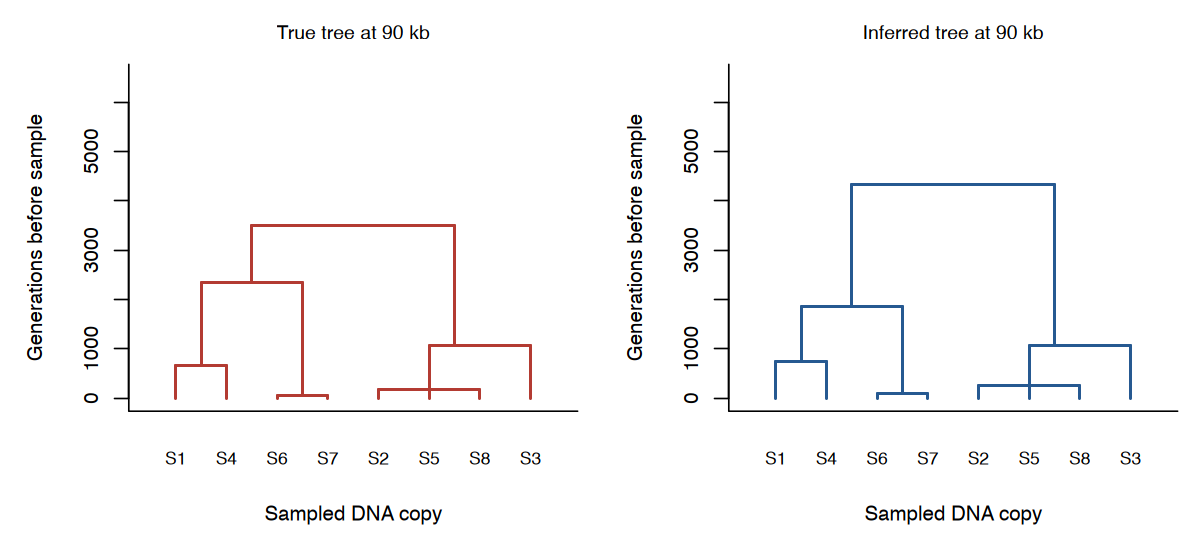

In [6]:
position <- 90000
drawFigure("population_arg_inference", function() {
    par(mfrow = c(1, 2), mar = c(4.6, 4.6, 2.3, .8))
    ymax <- max(truth$intervals$tmrca, estimated$intervals$tmrca) * 1.07
    k <- findInterval(position, truth$intervals$left)
    drawTree(truth$localTrees[[k]], "True tree at 90 kb", truth_color, ymax)
    k <- findInterval(position, estimated$intervals$left)
    drawTree(estimated$localTrees[[k]], "Inferred tree at 90 kb", estimate_color, ymax)
})
validation <- compareAncestry(dated, sequences)
print(round(validation$lengthWeighted, 3))


## A summary loses information about carrier identities

Count derived copies in all eight haplotypes. The source-derived
`expectedSFS` prediction is $E(\xi_i)=4N_e\mu L/i$. Its inputs are the
generating parameters; it is an expectation, not the realized spectrum.

Now mimic SNP discovery in only the first two haplotypes. Keep a site
only if those two copies differ, then still count its derived alleles
among all eight. This changes which sites enter the same sample's SFS.
The sampled population and its true ancestry are unchanged.


       all_variants discovered_variants 
                262                  39 


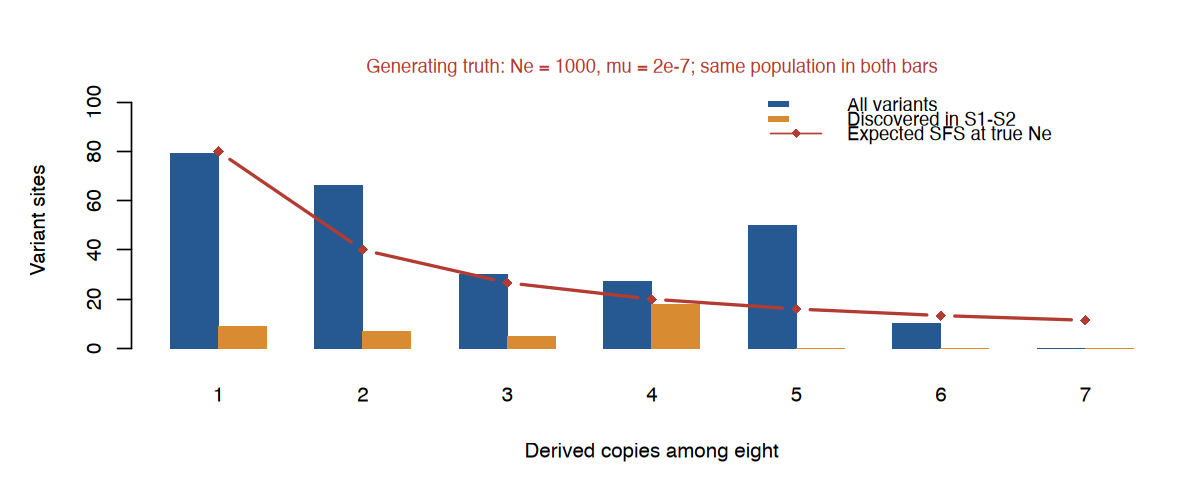

In [7]:
H <- observed$haplotypes
counts <- colSums(H)
all_sfs <- tabulate(counts, nrow(H) - 1L)
discovered <- H[1, ] != H[2, ]
discovered_sfs <- tabulate(counts[discovered], nrow(H) - 1L)
expectation <- expectedSFS(nrow(H), design$Ne, design$mutation_rate, design$length)
drawFigure("population_arg_spectrum", function() {
    par(mar = c(4.7, 4.7, 3.3, 1), bg = "white")
    x <- barplot(rbind(all_sfs, discovered_sfs), beside = TRUE,
        col = c(estimate_color, "#D88B31"), border = NA,
        names.arg = seq_len(nrow(H) - 1L), xlab = "Derived copies among eight",
        ylab = "Variant sites", ylim = c(0, max(all_sfs, expectation) * 1.3))
    lines(colMeans(x), expectation, col = truth_color, type = "b", pch = 18, lwd = 2)
    legend("topright", c("All variants", "Discovered in S1-S2", "Expected SFS at true Ne"),
        fill = c(estimate_color, "#D88B31", NA), border = NA,
        col = c(NA, NA, truth_color), lty = c(NA, NA, 1),
        pch = c(NA, NA, 18), bty = "n", cex = .9, y.intersp = 1.6)
    mtext("Generating truth: Ne = 1000, mu = 2e-7; same population in both bars",
          side = 3, line = .6, col = truth_color, cex = .9)
}, height = 4)
print(c(all_variants = sum(all_sfs), discovered_variants = sum(discovered_sfs)))


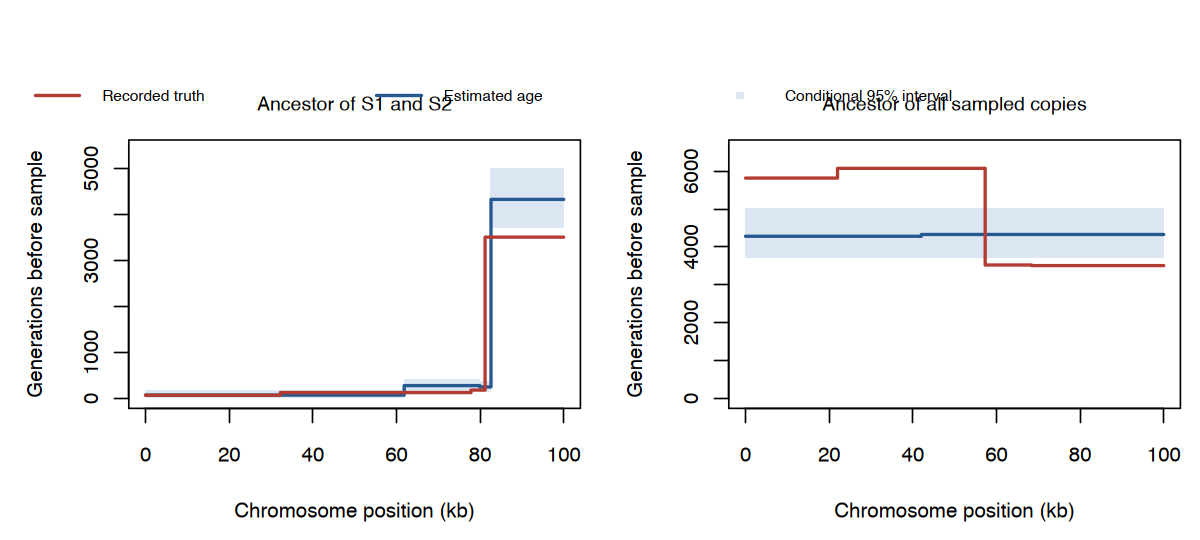

In [8]:
drawFigure("population_arg_ages", function() {
    par(mfrow = c(1, 2), mar = c(4.7, 4.6, 2.6, .7), oma = c(0, 0, 2.4, 0))
    for (field in c("pair_time", "tmrca")) {
        node_field <- if (field == "pair_time") "pair_node" else "root_node"
        interval <- estimated$intervals
        nodes <- interval[[node_field]]
        bounds <- t(vapply(nodes, function(node) {
            p <- dated$dating$posterior[node + 1L, ]
            vapply(c(.025, .975), function(q)
                dated$dating$timepoints[which(cumsum(p) >= q)[1L]], 0)
        }, c(0, 0)))
        x <- c(interval$left, tail(interval$right, 1L))/1000
        y <- c(interval[[field]], tail(interval[[field]], 1L))
        plot(NA, xlim = c(0, observed$sequenceLength/1000),
            ylim = c(0, max(truth$intervals[[field]], bounds) * 1.08),
            xlab = "Chromosome position (kb)", ylab = "Generations before sample",
            main = if (field == "pair_time") "Ancestor of S1 and S2" else
                "Ancestor of all sampled copies", cex.main = .95)
        for (j in seq_len(nrow(interval))) rect(interval$left[j]/1000, bounds[j,1],
            interval$right[j]/1000, bounds[j,2], col = "#DCE6F2", border = NA)
        lines(x, y, type = "s", col = estimate_color, lwd = 2)
        true <- truth$intervals
        lines(c(true$left, tail(true$right,1))/1000,
              c(true[[field]], tail(true[[field]],1)), type = "s", col = truth_color, lwd = 2)
    }
    par(xpd = NA)
    legend(grconvertX(.5, "ndc", "user"), grconvertY(.99, "ndc", "user"),
        c("Recorded truth", "Estimated age", "Conditional 95% interval"),
        col = c(truth_color, estimate_color, "#DCE6F2"),
        lty = c(1,1,NA), lwd = c(2,2,NA), pch = c(NA,NA,15),
        xjust = .5, yjust = 1, horiz = TRUE, bty = "n", cex = .75)
})


In [9]:
# Refining the time grid checks numerical resolution.
finer <- dateAncestry(inferred, mutation_rate, prior_size, timepoints = 80L)
grid_change <- mean(abs(dated$dating$mean - finer$dating$mean)[
    !dated$nodes$id %in% dated$sampleIds])
print(c(mean_age_change_with_finer_grid = grid_change))


mean_age_change_with_finer_grid 
                       3.777367 


The inferred trees reproduce all observed alleles. Several ancestral
histories can explain those alleles, so sequence reconstruction and recovery
of the true genealogy are separate checks. The comparison measures clade
agreement and age errors over genomic length.

The age intervals condition on inferred topology, mutation rate and the
diversity-based size estimate. Their uncertainty covers node dates within
that fitted model. The red curves show the generating history independently.

Pritchard, Sections 2.2, 2.3 and 3.3; Kelleher et al. (2019);
Wohns et al. (2022); [tsinfer](https://tskit.dev/tsinfer/docs/stable/inference.html)
and [tsdate methods](https://tskit.dev/tsdate/docs/stable/methods.html).
hpgR adapts the supplied algorithms from Daniel Nachun's tskitR.
